In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
import re
from cycler import cycler

servicecolors = ["#115e67", "#f0b434", "#ff5733", "#800000"]
# Guardar los colores como un cycler global
plt.rcParams['axes.prop_cycle'] = cycler(color=servicecolors)
# ==========================================
#  CONFIGURACIÓN DEL PARSEO
# ==========================================
rOOT_DIR = "./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/"
configs = "QUIC_PerformaceRR"

BASE_DIR = os.path.join(rOOT_DIR, configs)

SWEEP_DIR_PATTERN = "CAP**"
ITERS = "ITER**"
FEATURES = "**"
IDX_TIME = 0  
IDX_DATA = 1 
HAS_HEADER = False 
TIME_MULT_FACTOR = 1e-3
STREAMS_INFO = {
    "1_1": "Stream 1", 
    "1_2": "Stream 2"
}




In [ ]:
import os
import glob
import numpy as np
import pandas as pd


iters_a_ignorar = {}



def process_stream_logs(gamma_folder, suffix_stream):
    """
    Lee logClient_X_Y.log y logServer_X_Y.log de todas las iteraciones en gamma_folder,
    las cruza y calcula el retardo. Devuelve un array de delays concatenados.
    suffix_stream: ejemplo "1_1" o "1_2"
    """

    all_tx_times = []
    all_rx_times = []

    # Iterar sobre todas las iteraciones
    iters_pattern = os.path.join(gamma_folder, "*")  # cada carpeta dentro de gamma_folder es una iter
    iter_folders = sorted(glob.glob(iters_pattern))

    if not iter_folders:
        print(f"No se encontraron iteraciones en {gamma_folder}")
        return np.nan

    for iter_folder in iter_folders:
        # if os.path.basename(iter_folder) in iters_a_ignorar:
        #     continue
        # if os.path.basename(iter_folder) != "ITER1":
        #     continue
        # print(">> Processing iter: ",iter_folder)
        # Paths de cliente y servidor dentro de esta iteración
        f_cli_pattern = os.path.join(iter_folder, "go_client", f"logClient_{suffix_stream}.log")
        f_srv_pattern = os.path.join(iter_folder, "go_server", f"logServer_{suffix_stream}.log")

        files_cli = glob.glob(f_cli_pattern)
        files_srv = glob.glob(f_srv_pattern)

        if not files_cli or not files_srv:
            print(f"No se encontraron archivos en {iter_folder} para stream {suffix_stream}")
            continue

        f_cli = files_cli[0]
        f_srv = files_srv[0]

        try:
            df_tx = pd.read_csv(f_cli, header=None if not HAS_HEADER else 0, sep='\\s+', engine='python')
            df_rx = pd.read_csv(f_srv, header=None if not HAS_HEADER else 0, sep='\\s+', engine='python')

            tx_times = df_tx.iloc[:, IDX_TIME].values
            rx_times = df_rx.iloc[:, IDX_TIME].values

            all_tx_times.append(tx_times)
            all_rx_times.append(rx_times)

        except Exception as e:
            print(f"Error procesando {f_cli} / {f_srv}: {e}")
            continue

    if not all_tx_times or not all_rx_times:
        return np.nan

    # Concatenar todas las iteraciones
    tx_concat = np.concatenate(all_tx_times)
    rx_concat = np.concatenate(all_rx_times)

    # Calcular delay
    raw_delay = rx_concat - tx_concat
    delays_ms = raw_delay * TIME_MULT_FACTOR

    return delays_ms


def process_per_logs(gamma_folder):
    """
    Lee resultado_final.log de todas las iteraciones en gamma_folder
    y extrae el promedio de PER (tercer valor, índice 2).
    """
    all_per_values = []

    # Iterar sobre todas las iteraciones
    iters_pattern = os.path.join(gamma_folder, "*")
    iter_folders = sorted(glob.glob(iters_pattern))

    if not iter_folders:
        print(f"No se encontraron iteraciones en {gamma_folder}")
        return np.nan

    for iter_folder in iter_folders:
        # Path del archivo resultado_final.log
        f_per_pattern = os.path.join(iter_folder, "go_client", "resultado_final.log")
        files_per = glob.glob(f_per_pattern)

        if not files_per:
            # print(f"No se encontró resultado_final.log en {iter_folder}")
            continue

        f_per = files_per[0]

        try:
            # Leer el archivo (tiene una sola línea con valores separados por tabuladores)
            df_per = pd.read_csv(f_per, header=None, sep='\\s+', engine='python')
            
            # Extraer el tercer valor (índice 2) que es la PER
            per_value = df_per.iloc[0, 2]
            all_per_values.append(per_value)

        except Exception as e:
            print(f"Error procesando {f_per}: {e}")
            continue

    if not all_per_values:
        return np.nan

    # Retornar el promedio de todas las PER
    return np.mean(all_per_values)


In [ ]:
results = []
print(BASE_DIR)
cap_folders = glob.glob(os.path.join(BASE_DIR, SWEEP_DIR_PATTERN))

cap_folders.sort()

print(f"Encontradas {len(cap_folders)} carpetas de simulación.")

for folder in cap_folders:
    try:
        folder_name = os.path.basename(folder)
        cap_val = int(re.search(r"\d+", folder_name).group())
    except Exception:
        continue

    print(f"Procesando CAP: {cap_val}...")

    # Inicializamos siempre
    delays_1_1 = []
    delays_1_2 = []

    # -------- STREAM 1_1
    try:
        delays_1_1 = process_stream_logs(folder, "1_1")
    except Exception:
        pass

    # -------- STREAM 1_2
    try:
        delays_1_2 = process_stream_logs(folder, "1_2")
    except Exception:
        pass

    # Si no hay ningún delay, saltamos
    if len(delays_1_1) == 0 and len(delays_1_2) == 0:
        continue

    results.append({
        "cap_sweep": cap_val,
        "delay_stream_1": delays_1_1,
        "delay_1_1_mean": np.mean(delays_1_1) if len(delays_1_1) > 0 else np.nan,
        "delay_1_1_std":  np.std(delays_1_1) if len(delays_1_1) > 0 else np.nan,
        "delay_stream_2": delays_1_2,
        "delay_1_2_mean": np.mean(delays_1_2) if len((delays_1_2)) > 0 else np.nan,
        "delay_1_2_std":  np.std(delays_1_2) if len((delays_1_2)) > 0 else np.nan,
    })

# ---------- DataFrame final
df_res = pd.DataFrame(results)
df_res = df_res.sort_values(by="cap_sweep").reset_index(drop=True)

df_res[[
    "cap_sweep",
    "delay_1_1_mean",
    "delay_1_2_mean"
]]


<>:23: SyntaxWarning: invalid escape sequence '\g'
<>:23: SyntaxWarning: invalid escape sequence '\g'
C:\Users\khanf\AppData\Local\Temp\ipykernel_12492\3658806130.py:23: SyntaxWarning: invalid escape sequence '\g'
  plt.title("Impacto de M-LWDF: Barrido de Pesos ($\gamma$)\nEvaluación de Retardo Extremo a Extremo", fontsize=14)


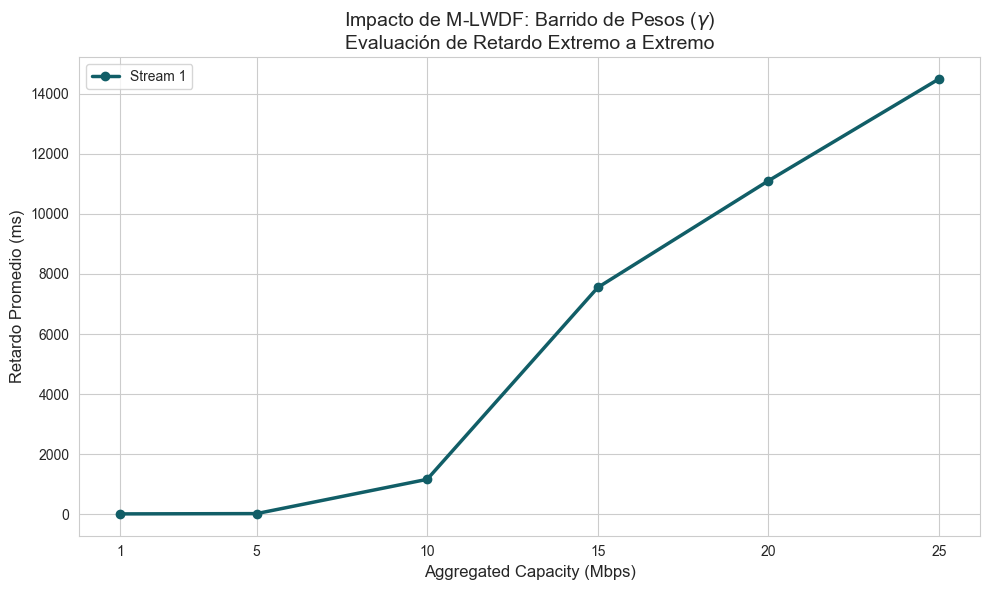

In [15]:
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")




x_data = 'cap_sweep'

    

if not df_res['delay_1_1_mean'].isna().all():
    plt.plot(df_res[x_data], df_res['delay_1_1_mean'], 
             marker='o', linewidth=2.5, label=STREAMS_INFO["1_1"])
    # plt.plot(df_res[x_data], df_res['delay_stream_1_std'], 
    #          marker='^', linestyle=':', color='orange', label=STREAMS_INFO["1_1"] + " Std Dev")

# if not df_res['delay_1_2_mean'].isna().all():
#     plt.plot(df_res[x_data], df_res['delay_1_2_mean'], 
#              marker='o', linewidth=2.5, label=STREAMS_INFO["1_2"])
#     # plt.plot(df_res[x_data], df_res['delay_stream_1_std'], 
#     #          marker='^', linestyle=':', color='orange', label=STREAMS_INFO["1_1"] + " Std Dev")

plt.title("Impacto de M-LWDF: Barrido de Pesos ($\gamma$)\nEvaluación de Retardo Extremo a Extremo", fontsize=14)
plt.xlabel("Aggregated Capacity (Mbps)", fontsize=12)
plt.ylabel("Retardo Promedio (ms)", fontsize=12)
plt.legend()
plt.xticks(df_res[x_data]) # Mostrar todos los puntos del eje X
plt.tight_layout()

plt.show()




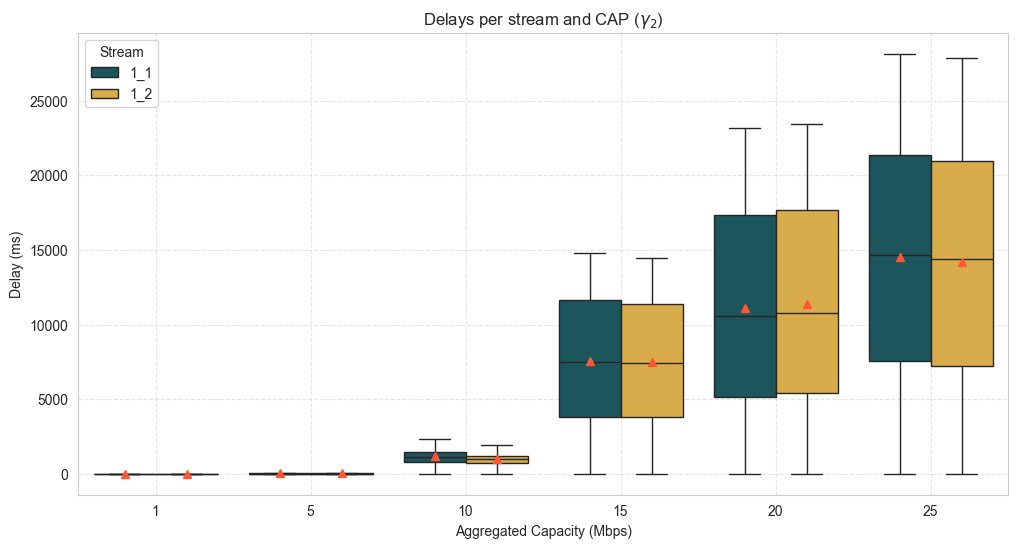

In [16]:

data_plot = []
x_data = 'cap_sweep'

    
for idx, row in df_res.iterrows():
    cap = row[x_data]
    
    # Stream 1
    for val in row['delay_stream_1']:
        data_plot.append({
            'cap': cap,
            'stream': '1_1',
            'delay': val
        })
    for val in row['delay_stream_2']:
            data_plot.append({
                'cap': cap,
                'stream': '1_2',
                'delay': val
        })

df_plot = pd.DataFrame(data_plot)

# Boxplot con Seaborn
plt.figure(figsize=(12,6))
sns.boxplot(x='cap', y='delay', hue='stream', data=df_plot, showmeans=True, showfliers=False)
plt.title(r"Delays per stream and CAP ($\gamma_2$)")
plt.xlabel(r"Aggregated Capacity (Mbps)")
plt.ylabel("Delay (ms)")  # Ajusta unidades si es necesario
plt.legend(title="Stream")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()



<>:46: SyntaxWarning: invalid escape sequence '\C'
<>:46: SyntaxWarning: invalid escape sequence '\C'
C:\Users\khanf\AppData\Local\Temp\ipykernel_12492\2738550917.py:46: SyntaxWarning: invalid escape sequence '\C'
  axes[idx].set_title(f"{schedname} ($\Cap$={cap_val})")


./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP1
Procesando CAP: 1 ...
  -> Window update average time: 143.08 ms
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP10
Procesando CAP: 10 ...
  -> Window update average time: 9.33 ms
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP15
Procesando CAP: 15 ...
  -> Window update average time: 8.67 ms
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP20
Procesando CAP: 20 ...
  -> Window update average time: 8.69 ms
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP25
Procesando CAP: 25 ...
  -> Window update average time: 8.73 ms
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP5
Procesando CAP: 5 ...
  -> Window update average time: 17.04 ms


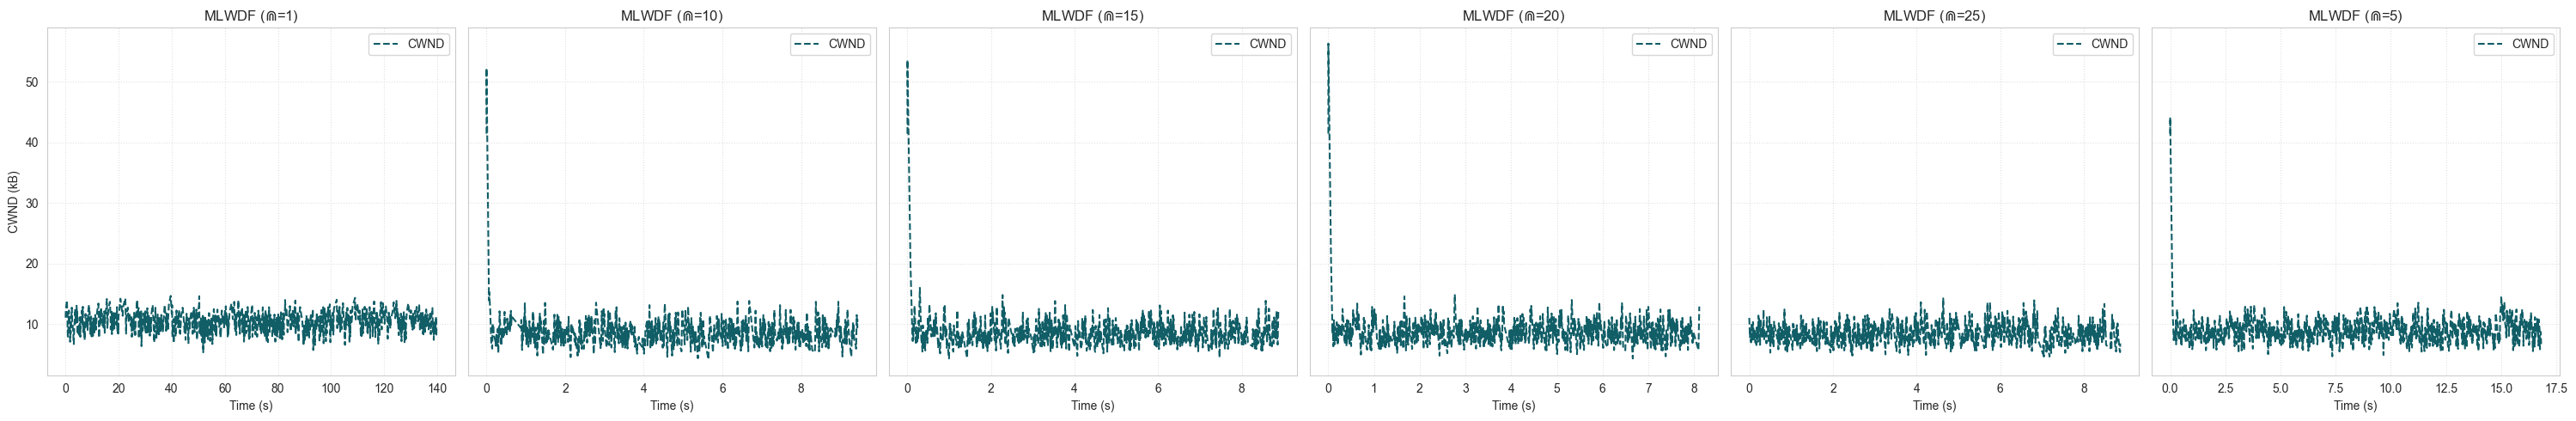

In [17]:

nstreams = 2
schedname = "MLWDF"

fig, axes = plt.subplots(1, len(cap_folders), figsize=(5 * len(cap_folders), 5), sharey=True)

if len(cap_folders) == 1:
    axes = [axes]

for idx, folder in enumerate(cap_folders): 
    print(folder)
    try:
        folder_name = os.path.basename(folder)
       
        cap_val = int(re.search(r"\d+", folder_name).group())
    except Exception as e:
        print(f"Saltando carpeta {folder}: No se pudo extraer CAP ({e})")
        continue 
        
    print(f"Procesando CAP: {cap_val} ...")

    stb_logs_pattern = os.path.join(folder, f"**", "LOGS_congestionWindow", f"maybeIncreaseCwnd.log")
    stb_found_list = glob.glob(stb_logs_pattern, recursive=True)
  
    if not stb_found_list:
        print(f"  -> No se encontró log en {folder}")
        continue

    logfile_path = stb_found_list[0]
    
    try:
        read_buff = pd.read_csv(logfile_path, delimiter="\t", names=["Time", "CWND" ])
    except pd.errors.EmptyDataError:
        print(f"  -> Archivo vacío: {logfile_path}")
        continue

    # Plotting
    if not read_buff.empty:
        start_time = read_buff["Time"].iloc[0]
        x_data = (read_buff["Time"] - start_time) * 1e-6
        y_data = read_buff["CWND"] * 1e-3
        window_update =np.mean(np.diff(x_data))
        print(f"  -> Window update average time: {window_update*1e3:.2f} ms")
        axes[idx].plot(x_data[0:1000], y_data[0:1000], linestyle='--', label=f"CWND")

   
    axes[idx].set_title(f"{schedname} ($\Cap$={cap_val})")
    axes[idx].set_xlabel("Time (s)")
    axes[idx].grid(True, linestyle=':', alpha=0.6)

    if idx == 0:
        axes[idx].set_ylabel("CWND (kB)")
    
    axes[idx].legend()

plt.tight_layout()
plt.show()

./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP1
Procesando CAP: 1 ...
Pacing rate medio (CAP=1): 19.56 Mbps
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP10
Procesando CAP: 10 ...
Pacing rate medio (CAP=10): 15.85 Mbps
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP15
Procesando CAP: 15 ...
Pacing rate medio (CAP=15): 15.94 Mbps
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP20
Procesando CAP: 20 ...
Pacing rate medio (CAP=20): 15.91 Mbps
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP25
Procesando CAP: 25 ...
Pacing rate medio (CAP=25): 15.91 Mbps
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP5
Procesando CAP: 5 ...
Pacing rate medio (CAP=5): 16.12 Mbps


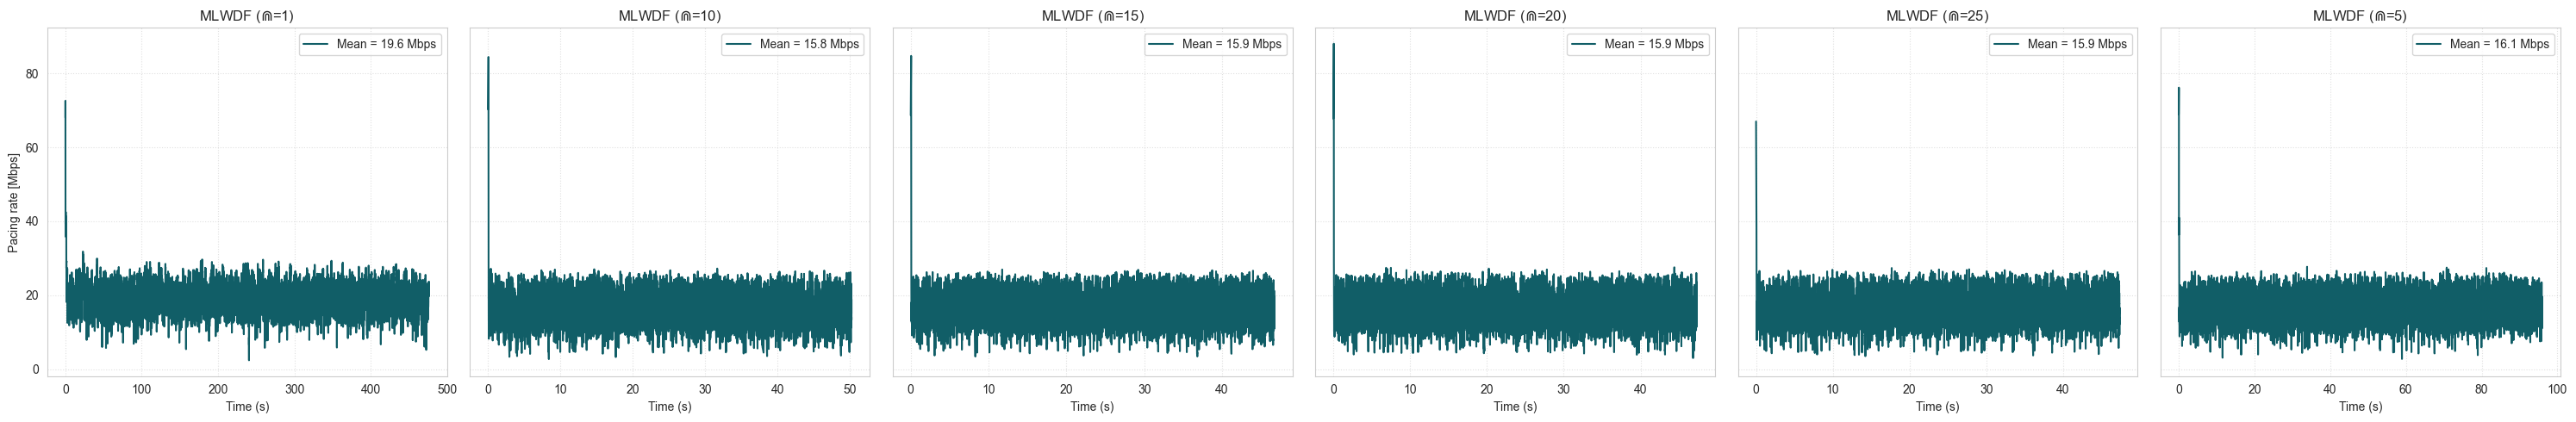

In [18]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt

nstreams = 2
schedname = "MLWDF"

def parse_rtt_to_seconds(x):
    """
    Convierte RTT con sufijo 'ms' o 's' a segundos (float).
    """
    if isinstance(x, str):
        x = x.strip()
        if x.endswith("ms"):
            return float(x.replace("ms", "")) * 1e-3
        if x.endswith("s"):
            return float(x.replace("s", ""))
    return float(x)

fig, axes = plt.subplots(
    1,
    len(cap_folders),
    figsize=(5 * len(cap_folders), 5),
    sharey=True
)

if len(cap_folders) == 1:
    axes = [axes]

for idx, folder in enumerate(cap_folders):
    print(folder)

    try:
        folder_name = os.path.basename(folder)
        cap_val = int(re.search(r"\d+", folder_name).group())
    except Exception as e:
        print(f"Saltando carpeta {folder}: No se pudo extraer CAP ({e})")
        continue

    print(f"Procesando CAP: {cap_val} ...")

    stb_logs_pattern = os.path.join(
        folder,
        f"**",
        "LOGS_congestionWindow",
        "logchannel.log"
    )

    stb_found_list = glob.glob(stb_logs_pattern, recursive=True)

    if not stb_found_list:
        print(f"  -> No se encontró log en {folder}")
        continue

    logfile_path = stb_found_list[0]

   
    df = pd.read_csv(
        logfile_path,
        sep=r"\s+",
        header=None,
        names=["ts_us", "min_rtt", "latest_rtt", "srtt", "cwnd"]
    )

    # Convertir RTTs a segundos
    for col in ["min_rtt", "latest_rtt", "srtt"]:
        df[col + "_s"] = df[col].apply(parse_rtt_to_seconds)

    # Tiempo relativo en segundos
    df["t_s"] = (df["ts_us"] - df["ts_us"].iloc[0]) * 1e-6

   
    df["pacing_rate_Bps"] = df["cwnd"] / df["srtt_s"]
    df["pacing_rate_Mbps"] = df["pacing_rate_Bps"] * 8 / 1e6

    mean_rate = df["pacing_rate_Mbps"].mean()
    print(f"Pacing rate medio (CAP={cap_val}): {mean_rate:.2f} Mbps")

    # ---------- PLOT ----------
    axes[idx].plot(
        df["t_s"],
        df["pacing_rate_Mbps"],
        label=f"Mean = {mean_rate:.1f} Mbps"
    )

    axes[idx].set_title(f"{schedname} ($\\Cap$={cap_val})")
    axes[idx].set_xlabel("Time (s)")
    axes[idx].grid(True, linestyle=":", alpha=0.6)
    axes[idx].legend()

    if idx == 0:
        axes[idx].set_ylabel("Pacing rate [Mbps]")

plt.tight_layout()
plt.show()



Procesando TX Throughput (CAP=1)
  -> Throughput medio: 0.50 Mbps
  -> Throughput medio: 0.50 Mbps
 => Total Throughput medio: 1.01 Mbps

Procesando TX Throughput (CAP=10)
  -> Throughput medio: 4.78 Mbps
  -> Throughput medio: 4.79 Mbps
 => Total Throughput medio: 9.57 Mbps

Procesando TX Throughput (CAP=15)
  -> Throughput medio: 5.17 Mbps
  -> Throughput medio: 5.15 Mbps
 => Total Throughput medio: 10.31 Mbps

Procesando TX Throughput (CAP=20)
  -> Throughput medio: 5.10 Mbps
  -> Throughput medio: 5.07 Mbps
 => Total Throughput medio: 10.18 Mbps

Procesando TX Throughput (CAP=25)
  -> Throughput medio: 5.07 Mbps
  -> Throughput medio: 5.11 Mbps
 => Total Throughput medio: 10.18 Mbps

Procesando TX Throughput (CAP=5)
  -> Throughput medio: 2.50 Mbps
  -> Throughput medio: 2.51 Mbps
 => Total Throughput medio: 5.01 Mbps


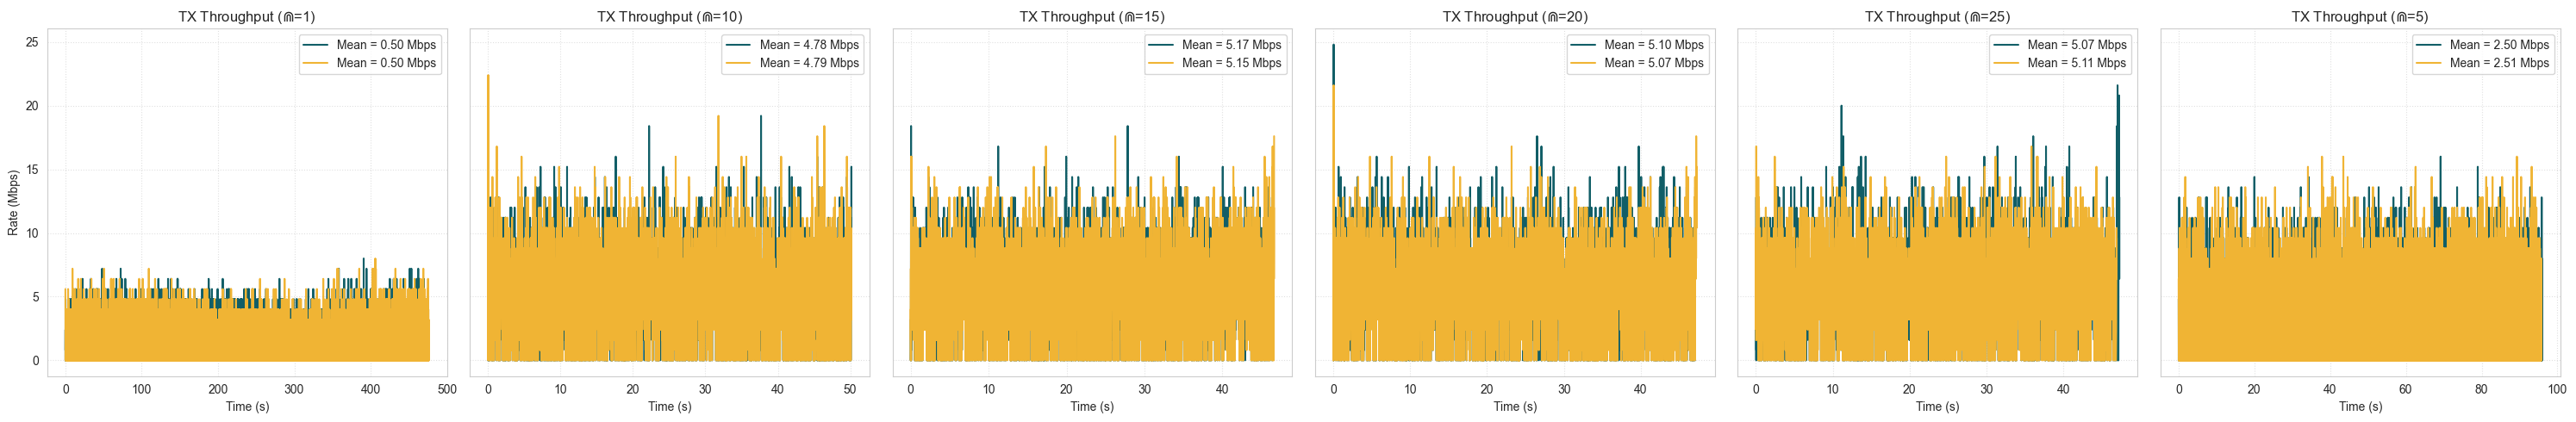

In [19]:
import os
import glob
import re
import numpy as np
import matplotlib.pyplot as plt

window = 0.01  # 10 ms

fig, axes = plt.subplots(
    1,
    len(cap_folders),
    figsize=(5 * len(cap_folders), 5),
    sharey=True
)

if len(cap_folders) == 1:
    axes = [axes]

for idx, folder in enumerate(cap_folders):
    try:
        folder_name = os.path.basename(folder)
        cap_val = int(re.search(r"\d+", folder_name).group())
    except Exception as e:
        print(f"Saltando carpeta {folder}: {e}")
        continue

    print(f"\nProcesando TX Throughput (CAP={cap_val})")

    tx_pattern = os.path.join(
        folder,
        "**",
        "go_server",
        "logServer_1_*.log"
    )

    tx_found = glob.glob(tx_pattern, recursive=True)

    if not tx_found:
        print(f"  -> No se encontró trazas_tx.log en {folder}")
        continue
    mean_tp_tot = []
    for tx_file in tx_found:    
   

        nTx = np.loadtxt(tx_file)

        # Tiempo relativo en segundos
        nTx[:, 0] = (nTx[:, 0] - nTx[0, 0]) * 1e-6
        time_end = nTx[-1, 0]

        Thput = []
        time_axis = []

        init = 0.0
        end = window

        while end <= time_end:
            mask = (nTx[:, 0] >= init) & (nTx[:, 0] < end)
            total_bytes = np.sum(nTx[mask, 1])

            throughput_Mbps = (total_bytes * 8) / window * 1e-6
            Thput.append(throughput_Mbps)
            time_axis.append(init + window / 2)

            init += window
            end += window

        mean_tp = np.mean(Thput)
        mean_tp_tot.append(mean_tp)
        print(f"  -> Throughput medio: {mean_tp:.2f} Mbps")

        # --------- PLOT ----------
        axes[idx].plot(
            time_axis,
            Thput,
            label=f"Mean = {mean_tp:.2f} Mbps"
        )

        axes[idx].set_title(f"TX Throughput ($\\Cap$={cap_val})")
        axes[idx].set_xlabel("Time (s)")
        axes[idx].grid(True, linestyle=":", alpha=0.6)
        axes[idx].legend()

        if idx == 0:
            axes[idx].set_ylabel("Rate (Mbps)")
    print(f" => Total Throughput medio: {np.sum(mean_tp_tot):.2f} Mbps")

plt.tight_layout()
plt.show()


./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP1
Archivo encontrado: ./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP1\ITER0\LOGS_congestionWindow\OnPacketLost.log
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP1\ITER0\LOGS_congestionWindow\OnPacketLost.log
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP1\ITER0\LOGS_congestionWindow\OnPacketLost.log
Archivo encontrado: ./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP1\ITER0\LOGS_congestionWindow\logchannel.log
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP1\ITER0\LOGS_congestionWindow\logchannel.log
./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP1\ITER0\LOGS_congestionWindow\logchannel.log
Archivo encontrado: ./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR\CAP1\ITER0\LOGS_congestionWindow\maybeIncreaseCwnd.log
./RESULTADOS_TESTBED_DSRC/

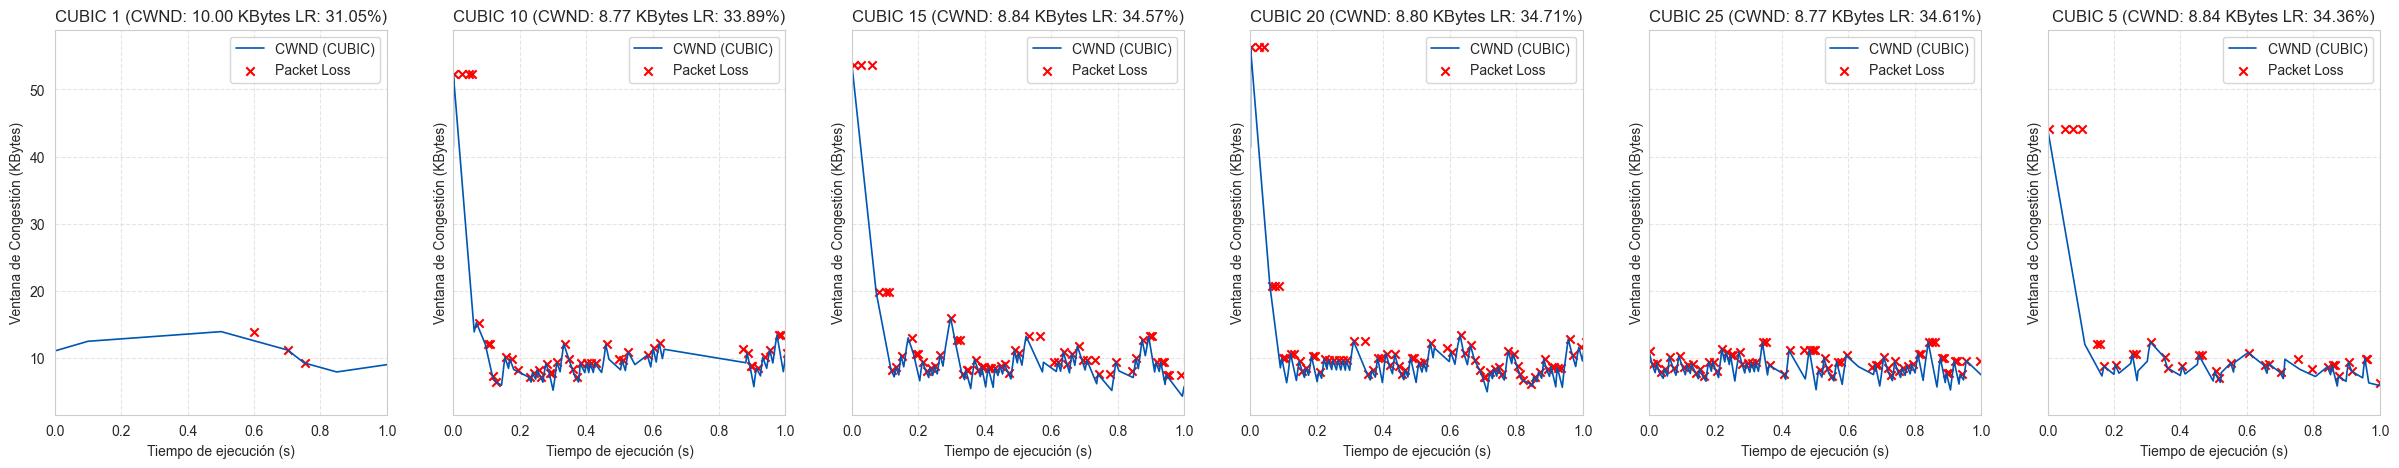

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# --- CONFIGURACIÓN ---
# Ajusta tus rutas
# local_path_c = "./Dockers/quic-apps/" # Define tu ruta base aquí
# file_lost = "go_client/LOGS_congestionWindow/OnPacketLost.log"
# file_cwnd = "go_client/LOGS_congestionWindow/maybeIncreaseCwnd.log"

# folder = local_path_c + "go_client/LOGS_congestionWindow/"
# stb_logs_pattern = os.path.join(folder, "*.log")


fig, axes = plt.subplots(
    1,
    len(cap_folders),
    figsize=(5 * len(cap_folders), 5),
    sharey=True
)

if len(cap_folders) == 1:
    axes = [axes]

for idx, folder in enumerate(cap_folders):
    try:
        folder_name = os.path.basename(folder)
        cap_val = int(re.search(r"\d+", folder_name).group())
    except Exception as e:
        print(f"Saltando carpeta {folder}: {e}")
        continue

    # print("Iniciando análisis de logs de congestión...")
    print(folder)
    stb_logs_pattern = os.path.join(folder, f"**", "LOGS_congestionWindow", f"**.log")
    stb_found_list = glob.glob(stb_logs_pattern, recursive=True)
    # print(f"Patrón de búsqueda: {stb_found_list}")
    # Buscar archivos
    # stb_found_list = glob.glob(stb_logs_pattern)
    # print(f"folders found: {stb_found_list}")
    if not stb_found_list:
        print(f"  -> No se encontró ningún log en {folder}")
    else:
        # Ordenar para consistencia (opcional)
        stb_found_list.sort()
        
        # Inicializar variables
        lost_files = None
        cwnd_file = None
        for f in stb_found_list:
            print(f"Archivo encontrado: {f}")
            print(f)
            base_name = os.path.basename(f)
            if base_name.startswith("OnPacketLost"):
                lost_files = f
                print(f)
            elif base_name.startswith("maybeIncreaseCwnd"):
                cwnd_file = f
                print(f)
            elif base_name.startswith("logchannel"):
                logchannel_file = f
                print(f)
        # Comprobación de que se encontraron ambos
        if lost_files is None:
            print("  -> No se encontró el log de pérdidas (OnPacketLost).")
        if cwnd_file is None:
            print("  -> No se encontró el log de congestion window (CWND).")

        try:
            df_lost = pd.read_csv(lost_files, sep='\t', usecols=[0], names=["Time"], engine='python')
        except Exception as e:
            # print(f"  -> Error al leer {lost_files}: {e}")
            continue

        # 2. Leer LOG DE CWND
        # Asumimos que maybeIncreaseCwnd.log tiene: Time, Bytes
        df_cwnd = pd.read_csv(cwnd_file, sep='\t', names=["Time", "CwndBytes"], engine='python')

        # Convertir a numérico por seguridad
        df_lost["Time"] = pd.to_numeric(df_lost["Time"], errors='coerce')
        df_cwnd["Time"] = pd.to_numeric(df_cwnd["Time"], errors='coerce')
        df_cwnd["CwndBytes"] = pd.to_numeric(df_cwnd["CwndBytes"], errors='coerce')



        # 3. SINCRONIZACIÓN (La mejora clave)
        # Ordenamos por tiempo (necesario para merge_asof)
        df_lost = df_lost.sort_values("Time")
        df_cwnd = df_cwnd.sort_values("Time")
        inter_arrival_time = np.mean(np.diff(df_cwnd["Time"]))
        # MERGE_ASOF: Para cada evento de pérdida, busca el valor de CWND 
        # registrado en el instante anterior más cercano ('backward').
        # Esto nos da la altura exacta de la X roja.
        df_lost_merged = pd.merge_asof(df_lost, df_cwnd, on="Time", direction="backward")

        # 4. ESTADÍSTICAS
        total_loss_events = len(df_lost)
        total_cwnd_updates = len(df_cwnd)
        total_events = total_loss_events + total_cwnd_updates

        loss_ratio = (total_loss_events / total_events * 100) if total_events > 0 else 0

        print(f"--- RESULTADOS ---")
        print(f"Eventos de pérdida (Loss): {total_loss_events}")
        print(f"Actualizaciones de CWND (Success): {total_cwnd_updates}")
        print(f"Ratio de Pérdida (aprox): {loss_ratio:.2f}%")
        print(f"Promedio de CWND: {df_cwnd['CwndBytes'].mean():.0f} bytes")
        print(f"Promedio ventana actualización: {inter_arrival_time*1e-3:.2f} ms")
        print(f"Capacidad del canal promedio (aprox): {(df_cwnd['CwndBytes'].mean()/inter_arrival_time):.2f} Mbps")

        # plt.figure(figsize=(12, 6))

        # Normalizar tiempo para que empiece en 0 (opcional, ayuda a leer mejor)
        start_time = df_cwnd["Time"].min()
        t_cwnd = df_cwnd["Time"] - start_time
        t_lost = df_lost_merged["Time"] - start_time



        axes[idx].plot(t_cwnd*1e-6, df_cwnd["CwndBytes"]/1000, label="CWND (CUBIC)", color="#0056b3", linewidth=1.2)
        axes[idx].set_xlim(0,1)  # Ajustar límite X al máximo tiempo registrado
        # y_vals_loss = [df_cwnd["CwndBytes"].mean()] * len(df_lost) # Los pintamos a altura media para verlos
        axes[idx].scatter(t_lost*1e-6, df_lost_merged["CwndBytes"]/1000, color="red", marker="x", label="Packet Loss")
        # axes[idx].scatter(t_lost*1e-6, y_vals_loss, color="red", marker="x", label="Packet Loss")
        axes[idx].set_title(f"CUBIC {cap_val} (CWND: {df_cwnd['CwndBytes'].mean()/1000:.2f} KBytes LR: {loss_ratio:.2f}%)")
        axes[idx].set_xlabel("Tiempo de ejecución (s)")
        axes[idx].set_ylabel("Ventana de Congestión (KBytes)")
        axes[idx].legend()
        axes[idx].grid(True, linestyle='--', alpha=0.5)
        # axes[idx].set_xlim(0,3)
plt.show()

C:\Users\khanf\AppData\Local\Temp\ipykernel_12492\1838131185.py:39: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x="Traffic", y="CwndKB", data=df_total,


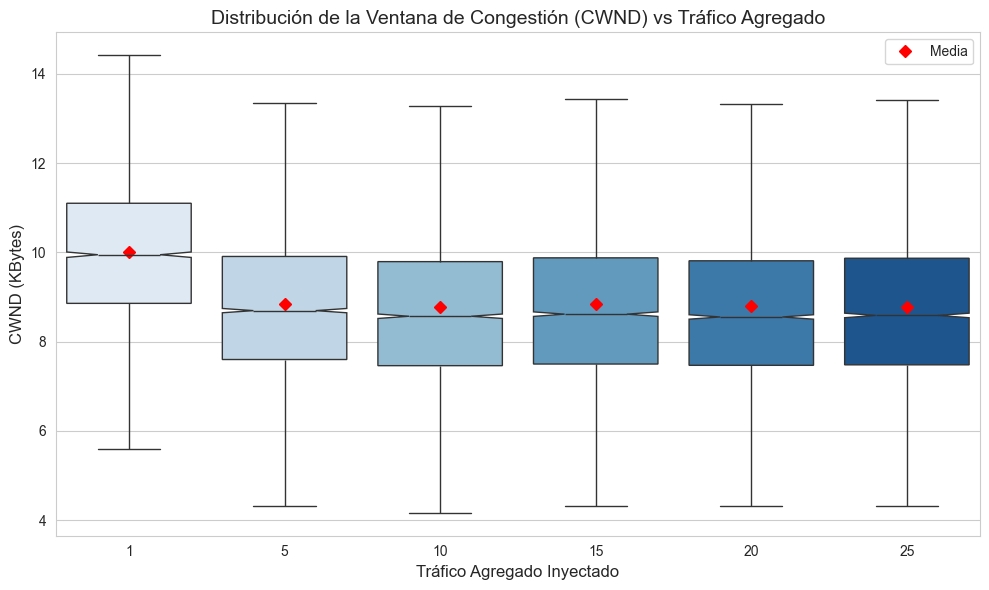

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns # Para que se vea más profesional
import numpy as np
import os
import re
import glob

# Lista para recolectar datos de todos los escenarios
all_data = []

for folder in cap_folders:
    try:
        folder_name = os.path.basename(folder)
        cap_val = int(re.search(r"\d+", folder_name).group())
        
        # Buscar archivos de CWND
        stb_logs_pattern = os.path.join(folder, f"**", "LOGS_congestionWindow", "maybeIncreaseCwnd.log")
        cwnd_files = glob.glob(stb_logs_pattern, recursive=True)
        
        if cwnd_files:
            df_temp = pd.read_csv(cwnd_files[0], sep='\t', names=["Time", "CwndBytes"], engine='python')
            df_temp["CwndKB"] = df_temp["CwndBytes"] / 1000
            df_temp["Traffic"] = cap_val # Etiqueta del escenario
            all_data.append(df_temp[["Traffic", "CwndKB"]])
            
    except Exception as e:
        print(f"Error procesando {folder}: {e}")

# Concatenar todos los datos en un solo DataFrame
df_total = pd.concat(all_data)

# --- CREACIÓN DE LA GRÁFICA PARA EL PAPER ---
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")

# Boxplot: Muestra Mediana, Cuartiles y Outliers
# El 'notch' ayuda a ver si las medianas son significativamente diferentes
ax = sns.boxplot(x="Traffic", y="CwndKB", data=df_total, 
                 palette="Blues", notch=True, showfliers=False) 

# Añadir un "Swarm" o "Strip" plot encima (opcional, para ver densidad)
# sns.stripplot(x="Traffic", y="CwndKB", data=df_total, color="black", size=1, alpha=0.3)

plt.title("Distribución de la Ventana de Congestión (CWND) vs Tráfico Agregado", fontsize=14)
plt.xlabel("Tráfico Agregado Inyectado", fontsize=12)
plt.ylabel("CWND (KBytes)", fontsize=12)

# Añadir el valor promedio como un punto para mayor claridad
means = df_total.groupby('Traffic')['CwndKB'].mean()
plt.plot(range(len(means)), means, color='red', marker='D', linestyle='None', label='Media')

plt.legend()
plt.tight_layout()
plt.show()

In [22]:
import pandas as pd
import numpy as np
import os

# --- PROCESAMIENTO MEJORADO ---
# 1. Leer LOG DE PÉRDIDAS (Usamos las dos columnas: Tiempo y Valor real)
df_lost = pd.read_csv(lost_files, sep='\t', names=["Time", "CwndLoss"], engine='python')

# 2. Leer LOG DE CWND
df_cwnd = pd.read_csv(cwnd_file, sep='\t', names=["Time", "CwndBytes"], engine='python')

# Limpieza y Sincronización
start_time = df_cwnd["Time"].min()

# Convertir a Segundos y KiB (Usando 1024)
df_cwnd["time_s"] = (df_cwnd["Time"] - start_time) * 1e-6
df_cwnd["cwnd_kb"] = df_cwnd["CwndBytes"] / 1000

df_lost["time_s"] = (df_lost["Time"] - start_time) * 1e-6
df_lost["cwnd_kb"] = df_lost["CwndLoss"] / 1000

# Exportar para TikZ (limitamos a 10s para que no pese demasiado)
df_cwnd[df_cwnd['time_s'] <= 50][["time_s", "cwnd_kb"]].to_csv("cwnd_tikz.csv", index=False)
df_lost[df_lost['time_s'] <= 50][["time_s", "cwnd_kb"]].to_csv("loss_tikz.csv", index=False)

print("CSVs generados con precisión real (sin merge).")

CSVs generados con precisión real (sin merge).


In [23]:
import pandas as pd
import glob
import os

# --- 1. CONFIGURACIÓN DE RUTAS ---
# Ajusta 'folder' a la ubicación de tus archivos


# Buscamos los archivos usando patrones


# --- 2. CARGA DE DATOS ---
# maybeIncreaseCwnd.log: [Timestamp, CwndBytes]
df_cwnd_raw = pd.read_csv(cwnd_file, sep='\t', names=["Time", "CwndBytes"])

# OnPacketLost.log: [Timestamp, CwndAtLoss]
df_loss_raw = pd.read_csv(lost_files, sep='\t', names=["Time", "CwndLoss"])

# --- 3. NORMALIZACIÓN Y PROCESAMIENTO ---
# Buscamos el tiempo de inicio para que la gráfica empiece en 0
t0 = df_cwnd_raw["Time"].min()

# Preparamos el DataFrame de la LÍNEA (CWND)
df_line = pd.DataFrame({
    "time_s": (df_cwnd_raw["Time"] - t0) * 1e-6,
    "cwnd_line": df_cwnd_raw["CwndBytes"] / 1024, # Convertimos a KiB
    "loss_mark": float('nan')                     # Columna vacía para esta parte
})

# Preparamos el DataFrame de las MARCAS (Pérdidas)
df_marks = pd.DataFrame({
    "time_s": (df_loss_raw["Time"] - t0) * 1e-6,
    "cwnd_line": float('nan'),                    # Columna vacía para esta parte
    "loss_mark": df_loss_raw["CwndLoss"] / 1024   # Convertimos a KiB
})

# --- 4. EL MERGE ORDENADO ---
# Concatenamos ambos DataFrames y los ordenamos cronológicamente
df_final = pd.concat([df_line, df_marks]).sort_values("time_s")

# --- 5. EXPORTACIÓN ---
# Guardamos solo los primeros 10 segundos para TikZ (opcional, ajusta si quieres más)
df_export = df_final[df_final["time_s"] <= 50]

df_export.to_csv("datos_merge.csv", index=False)

print(f"Procesado finalizado.")
print(f"Archivo 'datos_merge.csv' generado con {len(df_export)} puntos.")

Procesado finalizado.
Archivo 'datos_merge.csv' generado con 4525 puntos.


In [24]:
import pandas as pd
import glob
import os

# --- 1. CONFIGURACIÓN ---
# folder = "./testbedv2x/channstats/ITER0/LOGS_congestionWindow/" 
# cwnd_path = glob.glob(os.path.join(folder, "maybeIncreaseCwnd*.log"))[0]
# loss_path = glob.glob(os.path.join(folder, "OnPacketLost*.log"))[0]
cwnd_file = "./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR/CAP1/ITER0/LOGS_congestionWindow/maybeIncreaseCwnd.log"
lost_files = "./RESULTADOS_TESTBED_DSRC/results_QUIC_Perf/results/QUIC_PerformaceRR/CAP1/ITER0/LOGS_congestionWindow/OnPacketLost.log"
# --- 2. CARGA Y RENOMBRADO ---
# Cargamos CWND
df_cwnd_raw = pd.read_csv(cwnd_file, sep='\t', names=["Time", "cwnd_kb"])

# OnPacketLost.log: [Timestamp, CwndAtLoss]
df_loss_raw = pd.read_csv(lost_files, sep='\t',names=["Time", "cwnd_kb"])

# --- 3. UNIFICACIÓN (2 columnas) ---
# Juntamos ambos y ordenamos por el timestamp original
# df_unificado = pd.concat([df_cwnd_raw, df_loss_raw]).sort_values("Time")
df_unificado = df_cwnd_raw

# --- 4. NORMALIZACIÓN ---
t0 = df_unificado["Time"].min()
df_unificado["time_s"] = (df_unificado["Time"] - t0) * 1e-6
df_unificado["cwnd_kb"] = df_unificado["cwnd_kb"] / 1000  # A KiB

# Nos quedamos solo con las 2 columnas deseadas
df_final = df_unificado[["time_s", "cwnd_kb"]]

# --- 5. EXPORTACIÓN ---
# Guardamos los primeros 10 segundos para un manejo ágil en TikZ
df_final[df_final["time_s"]<10].to_csv("datos_2col_CAP1.csv", index=False)

print(f"Archivo 'datos_2col_CAP1.csv' generado con {len(df_final[df_final['time_s'] <= 10])} puntos.")

Archivo 'datos_2col_CAP1.csv' generado con 76 puntos.


Pacing rate medio: 16.12 Mbps


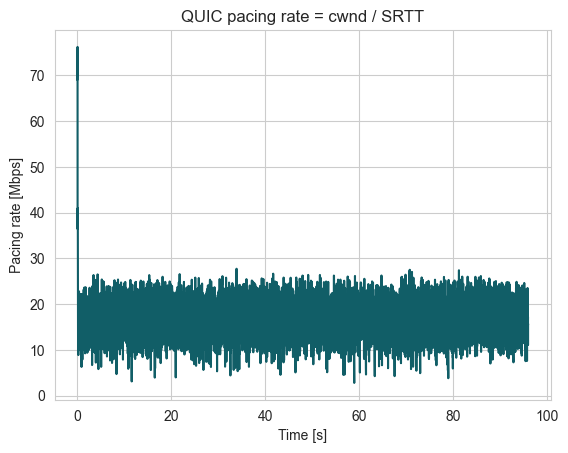

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# -------- CONFIG --------
# filename = folder + "/ITER10/LOGS_congestionWindow/logchannel.log"
# filename = "./Dockers/quic-apps/go_client/LOGS_congestionWindow/logchannel.log"
# ------------------------

# Leer fichero (separado por espacios)
df = pd.read_csv(
    logfile_path,
    sep=r"\s+",
    header=None,
    names=["ts_us", "min_rtt", "latest_rtt", "srtt", "cwnd"]
)

# Eliminar el sufijo 'ms' y convertir a float
for col in ["min_rtt", "latest_rtt", "srtt"]:
    df[col] = df[col].str.replace("ms", "", regex=False).astype(float)

# Convertir RTT a segundos
df["srtt_s"] = df["srtt"] * 1e-3

# Convertir timestamp a segundos relativos
df["t_s"] = (df["ts_us"] - df["ts_us"].iloc[0]) * 1e-6

# Calcular pacing rate
df["pacing_rate_Bps"] = df["cwnd"] / df["srtt_s"]
df["pacing_rate_Mbps"] = df["pacing_rate_Bps"] * 8 / 1e6

# Valor medio
mean_rate = df["pacing_rate_Mbps"].mean()

print(f"Pacing rate medio: {mean_rate:.2f} Mbps")

# -------- PLOT --------
plt.figure()
plt.plot(df["t_s"], df["pacing_rate_Mbps"])
plt.xlabel("Time [s]")
plt.ylabel("Pacing rate [Mbps]")
plt.title("QUIC pacing rate = cwnd / SRTT")
plt.grid(True)
plt.show()


In [26]:
import os
import glob
import re
import numpy as np
import pandas as pd

# ==================================================================
# FUNCIÓN AUXILIAR: Parsear RTT con sufijos
# ==================================================================
def parse_rtt_to_seconds(x):
    """Convierte RTT con sufijo 'ms' o 's' a segundos (float)."""
    if isinstance(x, str):
        x = x.strip()
        if x.endswith("ms"):
            return float(x.replace("ms", "")) * 1e-3
        if x.endswith("s"):
            return float(x.replace("s", ""))
    return float(x)

# ==================================================================
# CONFIGURACIÓN
# ==================================================================
window_throughput = 0.01  # Ventana de 10 ms para calcular throughput

# ==================================================================
# RECOPILACIÓN DE DATOS
# ==================================================================
resultados_completos = []

gamma_folders = glob.glob(os.path.join(BASE_DIR, SWEEP_DIR_PATTERN))
gamma_folders.sort()

print(f"\n{'='*60}")
print(f"GENERANDO ARCHIVO CSV CON TODOS LOS RESULTADOS")
print(f"{'='*60}\n")

for folder in gamma_folders:
    try:
        folder_name = os.path.basename(folder)
        capacidad = int(re.search(r"\d+", folder_name).group())
    except Exception:
        continue

    print(f"\n--- Procesando Capacidad: {capacidad} Mbps ---")

    # =====================================================
    # 1. DELAYS
    # =====================================================
    delays_1_1 = []
    delays_1_2 = []
    
    try:
        delays_1_1 = process_stream_logs(folder, "1_1")
        if isinstance(delays_1_1, np.ndarray) and len(delays_1_1) > 0:
            delay_1_mean = np.mean(delays_1_1)
            delay_1_std = np.std(delays_1_1)
        else:
            delay_1_mean = np.nan
            delay_1_std = np.nan
    except Exception as e:
        print(f"  Error en delay stream 1_1: {e}")
        delay_1_mean = np.nan
        delay_1_std = np.nan

    try:
        delays_1_2 = process_stream_logs(folder, "1_2")
        if isinstance(delays_1_2, np.ndarray) and len(delays_1_2) > 0:
            delay_2_mean = np.mean(delays_1_2)
            delay_2_std = np.std(delays_1_2)
        else:
            delay_2_mean = np.nan
            delay_2_std = np.nan
    except Exception as e:
        print(f"  Error en delay stream 1_2: {e}")
        delay_2_mean = np.nan
        delay_2_std = np.nan

    print(f"  Delay Stream 1: {delay_1_mean:.2f} ms (std: {delay_1_std:.2f})")
    print(f"  Delay Stream 2: {delay_2_mean:.2f} ms (std: {delay_2_std:.2f})")

    # =====================================================
    # 2. PACING RATE
    # =====================================================
    pacing_rate_mean = np.nan
    
    try:
        pacing_logs_pattern = os.path.join(folder, "**", "LOGS_congestionWindow", "logchannel.log")
        pacing_found = glob.glob(pacing_logs_pattern, recursive=True)
        
        if pacing_found:
            df_pacing = pd.read_csv(
                pacing_found[0],
                sep=r"\s+",
                header=None,
                names=["ts_us", "min_rtt", "latest_rtt", "srtt", "cwnd"]
            )
            
            # Convertir RTTs a segundos
            for col in ["min_rtt", "latest_rtt", "srtt"]:
                df_pacing[col + "_s"] = df_pacing[col].apply(parse_rtt_to_seconds)
            
            # Calcular pacing rate
            df_pacing["pacing_rate_Bps"] = df_pacing["cwnd"] / df_pacing["srtt_s"]
            df_pacing["pacing_rate_Mbps"] = df_pacing["pacing_rate_Bps"] * 8 / 1e6
            
            pacing_rate_mean = df_pacing["pacing_rate_Mbps"].mean()
            print(f"  Pacing Rate: {pacing_rate_mean:.2f} Mbps")
        else:
            print(f"  Pacing Rate: No disponible")
    except Exception as e:
        print(f"  Error en pacing rate: {e}")

    # =====================================================
    # 3. PER (Packet Error Rate)
    # =====================================================
    per_mean = np.nan
    
    try:
        per_mean = process_per_logs(folder)
        if not np.isnan(per_mean):
            print(f"  PER: {per_mean:.3f}%")
        else:
            print(f"  PER: No disponible")
    except Exception as e:
        print(f"  Error en PER: {e}")

    # =====================================================
    # 4. THROUGHPUT
    # =====================================================
    throughput_1_mean = np.nan
    throughput_2_mean = np.nan
    
    # Throughput Stream 1
    try:
        tx_pattern_1 = os.path.join(folder, "**", "go_server", "logServer_1_1.log")
        tx_found_1 = glob.glob(tx_pattern_1, recursive=True)
        
        if tx_found_1:
            nTx = np.loadtxt(tx_found_1[0])
            nTx[:, 0] = (nTx[:, 0] - nTx[0, 0]) * 1e-6  # Tiempo relativo en segundos
            time_end = nTx[-1, 0]
            
            Thput = []
            init = 0.0
            end = window_throughput
            
            while end <= time_end:
                mask = (nTx[:, 0] >= init) & (nTx[:, 0] < end)
                total_bytes = np.sum(nTx[mask, 1])
                throughput_Mbps = (total_bytes * 8) / window_throughput * 1e-6
                Thput.append(throughput_Mbps)
                init += window_throughput
                end += window_throughput
            
            throughput_1_mean = np.mean(Thput) if Thput else np.nan
            print(f"  Throughput Stream 1: {throughput_1_mean:.2f} Mbps")
        else:
            print(f"  Throughput Stream 1: No disponible")
    except Exception as e:
        print(f"  Error en throughput stream 1: {e}")

    # Throughput Stream 2
    try:
        tx_pattern_2 = os.path.join(folder, "**", "go_server", "logServer_1_2.log")
        tx_found_2 = glob.glob(tx_pattern_2, recursive=True)
        
        if tx_found_2:
            nTx = np.loadtxt(tx_found_2[0])
            nTx[:, 0] = (nTx[:, 0] - nTx[0, 0]) * 1e-6  # Tiempo relativo en segundos
            time_end = nTx[-1, 0]
            
            Thput = []
            init = 0.0
            end = window_throughput
            
            while end <= time_end:
                mask = (nTx[:, 0] >= init) & (nTx[:, 0] < end)
                total_bytes = np.sum(nTx[mask, 1])
                throughput_Mbps = (total_bytes * 8) / window_throughput * 1e-6
                Thput.append(throughput_Mbps)
                init += window_throughput
                end += window_throughput
            
            throughput_2_mean = np.mean(Thput) if Thput else np.nan
            print(f"  Throughput Stream 2: {throughput_2_mean:.2f} Mbps")
        else:
            print(f"  Throughput Stream 2: No disponible")
    except Exception as e:
        print(f"  Error en throughput stream 2: {e}")

    # =====================================================
    # 5. AGREGAR A RESULTADOS
    # =====================================================
    resultados_completos.append({
        'capacidad_Mbps': capacidad,
        'delay_stream1_mean_ms': delay_1_mean,
        'delay_stream1_std_ms': delay_1_std,
        'delay_stream2_mean_ms': delay_2_mean,
        'delay_stream2_std_ms': delay_2_std,
        'pacing_rate_Mbps': pacing_rate_mean,
        'throughput_stream1_Mbps': throughput_1_mean,
        'throughput_stream2_Mbps': throughput_2_mean,
        'throughput_total_Mbps': throughput_1_mean + throughput_2_mean if not np.isnan(throughput_1_mean) and not np.isnan(throughput_2_mean) else throughput_1_mean if not np.isnan(throughput_1_mean) else throughput_2_mean,
        'per_mean': per_mean
    })

# ==================================================================
# CREAR DATAFRAME Y GUARDAR CSV
# ==================================================================
df_resultados = pd.DataFrame(resultados_completos)
df_resultados = df_resultados.sort_values(by='capacidad_Mbps').reset_index(drop=True)

# Nombre del archivo de salida
output_filename = f"resultados_{schedname}_{configs}.csv"

# Guardar CSV
df_resultados.to_csv(output_filename, index=False, float_format='%.3f')

print(f"\n{'='*60}")
print(f"✓ Archivo guardado: {output_filename}")
print(f"{'='*60}\n")

# Mostrar el DataFrame
print("Vista previa de los resultados:")
print(df_resultados)



GENERANDO ARCHIVO CSV CON TODOS LOS RESULTADOS


--- Procesando Capacidad: 1 Mbps ---
  Delay Stream 1: 6.04 ms (std: 5.39)
  Delay Stream 2: 6.24 ms (std: 5.47)
  Pacing Rate: 19.56 Mbps
  PER: 3.155%
  Throughput Stream 1: 0.50 Mbps
  Throughput Stream 2: 0.50 Mbps

--- Procesando Capacidad: 10 Mbps ---
  Delay Stream 1: 1157.80 ms (std: 492.16)
  Delay Stream 2: 1000.32 ms (std: 469.71)
  Pacing Rate: 15.85 Mbps
  PER: 9.216%
  Throughput Stream 1: 4.78 Mbps
  Throughput Stream 2: 4.79 Mbps

--- Procesando Capacidad: 15 Mbps ---
  Delay Stream 1: 7550.50 ms (std: 4316.57)
  Delay Stream 2: 7476.87 ms (std: 4241.29)
  Pacing Rate: 15.94 Mbps
  PER: 9.418%
  Throughput Stream 1: 5.17 Mbps
  Throughput Stream 2: 5.15 Mbps

--- Procesando Capacidad: 20 Mbps ---
  Delay Stream 1: 11106.00 ms (std: 6802.01)
  Delay Stream 2: 11392.88 ms (std: 6925.24)
  Pacing Rate: 15.91 Mbps
  PER: 9.443%
  Throughput Stream 1: 5.10 Mbps
  Throughput Stream 2: 5.07 Mbps

--- Procesando Capacidad: 25 Mb

In [27]:
# Guardar CSV
df_resultados.to_csv(output_filename, index=False, float_format='%.3f')

print(f"\n{'='*60}")
print(f"✓ Archivo guardado: {output_filename}")
print(f"{'='*60}\n")

# Mostrar el DataFrame
print("Vista previa de los resultados:")
print(df_resultados)



✓ Archivo guardado: resultados_MLWDF_QUIC_PerformaceRR.csv

Vista previa de los resultados:
   capacidad_Mbps  delay_stream1_mean_ms  delay_stream1_std_ms  \
0               1               6.036465              5.390139   
1               5              15.397275             17.223559   
2              10            1157.803139            492.155582   
3              15            7550.495511           4316.570680   
4              20           11105.999124           6802.007220   
5              25           14500.747016           8113.036900   

   delay_stream2_mean_ms  delay_stream2_std_ms  pacing_rate_Mbps  \
0               6.236507              5.470303         19.555471   
1              15.929409             15.506308         16.117363   
2            1000.317339            469.712124         15.845066   
3            7476.869348           4241.290727         15.943610   
4           11392.876441           6925.243974         15.905489   
5           14214.284804           8